# Módulo 6 — Decomposição de séries temporais

## Seção 3 — STL: algoritmo de decomposição sazonal e tendencial por LOESS

**Estado editorial:** capítulo didático para revisão. **Pré-requisitos:** Módulo 6, Seções 1–2; média móvel, regressão local ponderada, sazonalidade, resíduo e Python básico. **Convenção:** $y_t$ é a observação; $T_t$, tendência; $S_t$, sazonalidade; $R_t$, restante; $s$, período sazonal em **número de observações**. Este capítulo trata de uma série univariada, com amostragem regular e uma sazonalidade dominante.

**Controle de fontes.** O livro-base de MORETTIN e TOLOI, *Análise de séries temporais: modelos lineares univariados*, v. 1, cap. 3, §3.2, pp. 52–56 (páginas 71–75 do PDF do projeto), fundamenta a distinção entre tendência, sazonalidade, estimadores por filtros e LOWESS. O documento `mapeamento-conteudos-series-temporais.md`, *Aula 2 — Parte II — Decomposição STL e MSTL*, identifica STL como assunto das videoaulas. **A descrição detalhada de passes internos/externos e os experimentos deste texto são complementação didática**, fundamentada na formulação conhecida do método de Cleveland et al. (1990) e conferida operacionalmente com a implementação local do `statsmodels`; não se atribui essa sequência de passos às páginas mencionadas de Morettin e Toloi. O artigo original de Cleveland et al. é indicado para aprofundamento bibliográfico, **sem alegação de consulta direta ao artigo nesta elaboração**.

### Objetivos de aprendizagem

Ao concluir, você deverá compreender a limitação de uma sazonalidade fixa, explicar a alternância entre extração sazonal e suavização da tendência, interpretar o filtro passa-baixas e os subgrupos sazonais, reconhecer o papel das iterações robustas, utilizar `STL` do Statsmodels, conferir a identidade de reconstrução e avaliar as limitações metodológicas.

### 1. O problema que o STL procura resolver

Na decomposição clássica, geralmente se estima um efeito médio para cada estação, que é repetido de modo idêntico em todos os anos. Mas o perfil sazonal pode mudar. Por exemplo, o pico de consumo em um dado mês pode crescer de maneira diferente do pico de outro mês. **STL** (*Seasonal-Trend decomposition using LOESS*) permite estimar sazonalidade **variável ao longo do tempo**, enquanto a tendência também é suavizada localmente.

Partimos de uma decomposição **aditiva**:

$$
\boxed{y_t=T_t+S_t+R_t,\qquad t=1,\ldots,n.}
$$

- $T_t$ representa variação lenta de nível;
- $S_t$ representa variação repetitiva com período aproximado $s$, mas cuja forma/amplitude pode evoluir;
- $R_t=y_t-T_t-S_t$ reúne o que os dois componentes não explicaram.

Os componentes são **estimativas dependentes do procedimento e dos hiperparâmetros**. Não afirmamos que a decomposição estatística recupera exatamente mecanismos físicos únicos. O STL é aditivo na escala utilizada; para dados positivos com sazonalidade proporcional ao nível, pode-se estudar $\log y_t$ antes do ajuste, com os cuidados de reversão estudados no Módulo 5.

### 2. De onde vem o LOESS dentro do STL?

Na Seção 2 estudamos uma reta ajustada em torno de $t_0$:

$$
\min_{a,b}\sum_{i=1}^n w_i(t_0)\,[z_i-a-b(t_i-t_0)]^2,
\qquad \widehat z(t_0)=\widehat a.
$$

Os pesos dependem da distância até $t_0$. Uma escolha é o núcleo tricúbico:

$$
K(u)=\begin{cases}(1-|u|^3)^3,&|u|<1,\\0,&|u|\ge1.\end{cases}
$$

No STL, regressões locais dessa natureza são usadas para suavizar sequências diferentes: sub-séries sazonais, uma sequência passa-baixas e a série dessazonalizada. Os graus polinomiais, janelas e detalhes das bordas podem variar conforme a implementação; LOESS é uma **família de operações**, não uma fórmula única para todos os passos.

### 3. O que são as sub-séries sazonais?

Suponha dados mensais, de período $s=12$. Separe as observações por posição no calendário:

$$
\begin{aligned}
C_1&=(y_1,y_{13},y_{25},\ldots),\\
C_2&=(y_2,y_{14},y_{26},\ldots),\\
&\vdots\\
C_{12}&=(y_{12},y_{24},y_{36},\ldots).
\end{aligned}
$$

Cada linha acompanha **a mesma posição sazonal ao longo dos ciclos**. Ao suavizar $C_1$, por exemplo, permitimos que o efeito do primeiro mês evolua ao longo dos anos, em vez de impor um valor constante. Depois reunimos as sub-séries suavizadas na ordem temporal original.

Esse procedimento não atribui automaticamente toda variação lenta dos subgrupos à sazonalidade: uma componente de baixa frequência ainda precisa ser separada por filtragem. É essa a função do próximo passo.

### 4. Estrutura conceitual das iterações internas

Descreveremos uma **passagem interna** de forma sequencial. As letras $T_t^{(k)}$ e $S_t^{(k)}$ denotam estimativas após a iteração $k$, e não potências.

**Passo A — Retirar a tendência corrente.**

$$
D_t^{(k)}=y_t-T_t^{(k)}.
$$

Isso expõe principalmente a sazonalidade e o restante. Na primeira passagem pode-se partir de uma estimativa inicial simples de tendência; não precisamos presumir que ela seja verdadeira.

**Passo B — Suavizar os subgrupos sazonais.** Aplicamos regressão local a cada grupo $C_j$ construído com $D_t^{(k)}$ e os reunimos em uma sequência $C_t^{(k+1)}$. Esse componente preliminar ainda pode conter uma tendência suave indevida.

**Passo C — Aplicar um filtro passa-baixas.** Uma construção usual do STL emprega filtros de médias móveis sucessivos, de larguras $s$, $s$ e 3, seguidos de suavização LOESS passa-baixas. Designaremos o resultado por $L_t^{(k+1)}$. Por exemplo, uma média móvel de largura $s$ é

$$
M_s(C)_t=\frac1s\sum_{j\in J_t}C_{t+j},
$$

em que $J_t$ representa os deslocamentos de uma janela de $s$ observações, com alinhamento apropriado. Para períodos pares, é necessário cuidar do centro entre observações; as médias móveis sucessivas e os procedimentos de borda tratam esse alinhamento.

**Passo D — Separar o efeito sazonal da parte lenta.**

$$
\boxed{S_t^{(k+1)}=C_t^{(k+1)}-L_t^{(k+1)}.}
$$

Subtraímos a parte lenta para evitar que a estimativa sazonal absorva a tendência. Essa subtração **não** impõe necessariamente soma exatamente zero em cada bloco finito quando as sazonalidades variam e as bordas exigem extrapolação.

**Passo E — Retirar a sazonalidade e reajustar a tendência.**

$$
A_t^{(k+1)}=y_t-S_t^{(k+1)},\qquad
T_t^{(k+1)}=\operatorname{LOESS}_{\mathrm{tend}}(A_t^{(k+1)}).
$$

Esse é o componente dessazonalizado usado para a regressão local da tendência. Repetimos A–E para permitir que os dois estimadores se ajustem um ao outro. **A expressão com LOESS é uma definição operacional**, não uma igualdade probabilística de médias verdadeiras.

```mermaid
flowchart TD
    A[Serie y e tendencia atual] --> B[Retirar tendencia]
    B --> C[Suavizar subseries sazonais por LOESS]
    C --> D[Extrair componente passa-baixas]
    D --> E[Calcular sazonalidade C menos L]
    E --> F[Dessazonalizar y menos S]
    F --> G[Suavizar tendencia por LOESS]
    G --> H{Mais iteracoes internas?}
    H -->|Sim| B
    H -->|Nao| I[Calcular residuo y menos T menos S]
```

*Figura conceitual 3.1 — Passagens internas do STL. O diagrama sintetiza a lógica matemática; não pretende documentar todas as decisões numéricas de uma implementação específica.*

### 5. Iterações externas: tornar o procedimento robusto

Uma observação excepcional pode distorcer regressões locais. STL pode usar um **laço externo robusto**, que reduz a influência dos pontos cujos resíduos são muito grandes. Depois de uma decomposição interna, sejam

$$
R_t=y_t-\widehat T_t-\widehat S_t,
\qquad m=\operatorname{mediana}(|R_1|,\ldots,|R_n|).
$$

Definimos a distância padronizada $u_t=|R_t|/(6m)$, para $m>0$. Uma regra de pesos biesquadrados frequentemente utilizada é

$$
\boxed{q_t=\begin{cases}(1-u_t^2)^2,&0\le u_t<1,\\0,&u_t\ge1.\end{cases}}
$$

Assim, resíduos grandes recebem menos peso nas próximas suavizações. O fator 6 atua como escala de robustificação; **não** é um limiar de detecção de anomalias válido universalmente. Se a mediana é zero, a rotina precisa de convenção especial para evitar divisão por zero. O peso pode depender da implementação e dos parâmetros configurados.

**Exemplo numérico de peso.** Se $m=2$ e um resíduo tem módulo 6, então $u=6/(6\cdot2)=1/2$ e $q=(1-1/4)^2=9/16=0{,}5625$. Se o resíduo tivesse módulo 12, $u=1$ e o peso seria zero. O algoritmo continua produzindo uma decomposição, mas a interpretação de um choque individual depende do contexto: nem todo valor extremo é erro.

### 6. Configuração das janelas e suas consequências

No `statsmodels.tsa.seasonal.STL`, as opções `period`, `seasonal`, `trend`, `low_pass` e `robust` controlam aspectos diferentes:

| Parâmetro | Papel | Efeito de escolhas inadequadas |
|---|---|---|
| `period=s` | Número de observações por ciclo | Agrupamentos sazonais errados; componentes confundidos |
| `seasonal` | Largura de suavização sazonal (ímpar) | Curta: adapta-se demais; longa: perde evolução da sazonalidade |
| `trend` | Largura de suavização da tendência (ímpar) | Curta: absorve oscilações; longa: esconde mudanças de nível |
| `low_pass` | Largura da suavização de baixa frequência (ímpar) | Pode deixar tendência na sazonalidade ou remover mudanças legítimas |
| `robust=True` | Habilita reponderação por resíduos | Pode proteger a tendência de choques, mas não soluciona mudanças de regime |

A implementação fornece escolhas padrão para algumas janelas, mas é importante registrar os valores **efetivamente utilizados**. Exigir janelas ímpares e suficientemente grandes não deve ser confundido com exigir que o período sazonal seja ímpar: `period=12` é perfeitamente legítimo.

### 7. Python: um experimento com uma sazonalidade e um choque

**Dependências:** `numpy`, `pandas`, `matplotlib` e `statsmodels`. `Pandas` guarda datas e facilita confirmar a frequência mensal; `NumPy` cria os vetores; `Statsmodels` executa o STL; `Matplotlib` desenha as componentes. O código foi testado em Statsmodels 0.14.6. Para reproduzir também os gráficos, utilize o script `modulo_06_secoes_03_04_exemplos.py` incluído no pacote.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import STL

rng = np.random.default_rng(20261119)
n = 240
t = np.arange(n)
T = 18 + 0.055*t + 1.8*np.sin(2*np.pi*t/170)
S = (3.1*np.sin(2*np.pi*t/12) + 1.2*np.cos(4*np.pi*t/12))*(1+0.002*t)
ruido = rng.normal(0, 0.65, n)
ruido[128] += 16  # choque pontual deliberado
serie = pd.Series(T + S + ruido,
                 index=pd.date_range('2006-01-01', periods=n, freq='MS'))

normal = STL(serie, period=12, seasonal=13,
             trend=23, low_pass=13, robust=False).fit()
robusto = STL(serie, period=12, seasonal=13,
              trend=23, low_pass=13, robust=True).fit()

# A decomposicao e aditiva na escala de entrada.
assert np.allclose(serie, robusto.trend + robusto.seasonal + robusto.resid)
print('Peso do choque:', robusto.weights.iloc[128])
print('Erro de tendencia, com robustez:', abs(robusto.trend.iloc[128] - T[128]))
print('Erro de tendencia, sem robustez:', abs(normal.trend.iloc[128] - T[128]))

fig, axes = plt.subplots(3, 1, figsize=(9, 7), sharex=True)
axes[0].plot(serie.index, serie, lw=0.8); axes[0].set_title('Observado')
axes[1].plot(serie.index, robusto.trend, label='Estimada')
axes[1].plot(serie.index, T, '--', label='Geradora')
axes[1].legend(); axes[1].set_title('Tendencia')
axes[2].plot(serie.index, robusto.seasonal); axes[2].set_title('Sazonalidade estimada')
plt.tight_layout()
plt.show()

`freq='MS'` representa início de mês; os 12 passos correspondem a 12 meses. `fit()` estima as componentes; `robusto.weights` devolve pesos calculados pela reponderação; `np.allclose` valida numericamente a identidade **de reconstrução**, e não a correção estatística dos componentes.

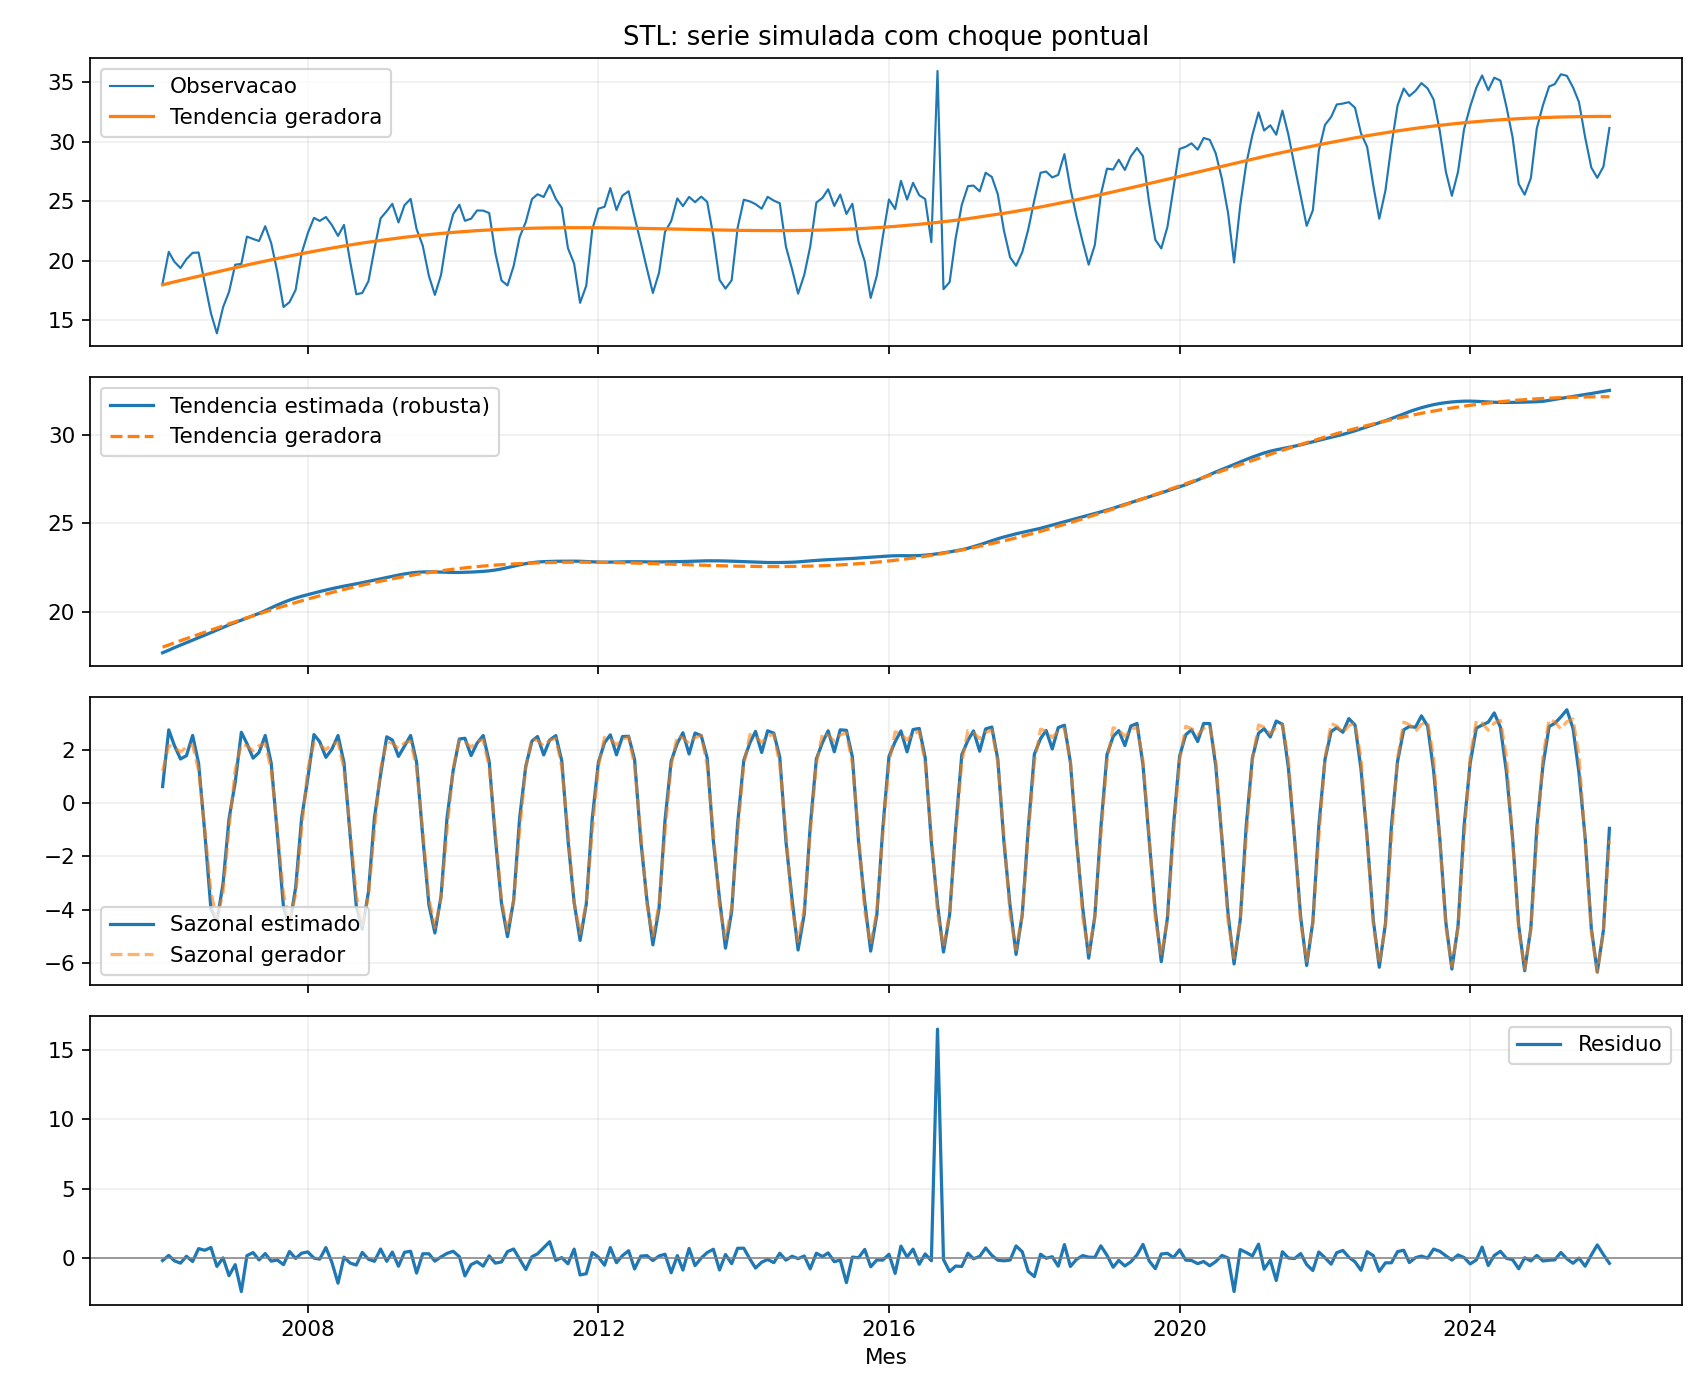

*Figura 3.2 — Série mensal sintética, tendência conhecida da simulação, tendência STL, sazonalidade STL e resíduos. A possibilidade de comparar com a verdade geradora existe apenas porque o experimento foi simulado.*

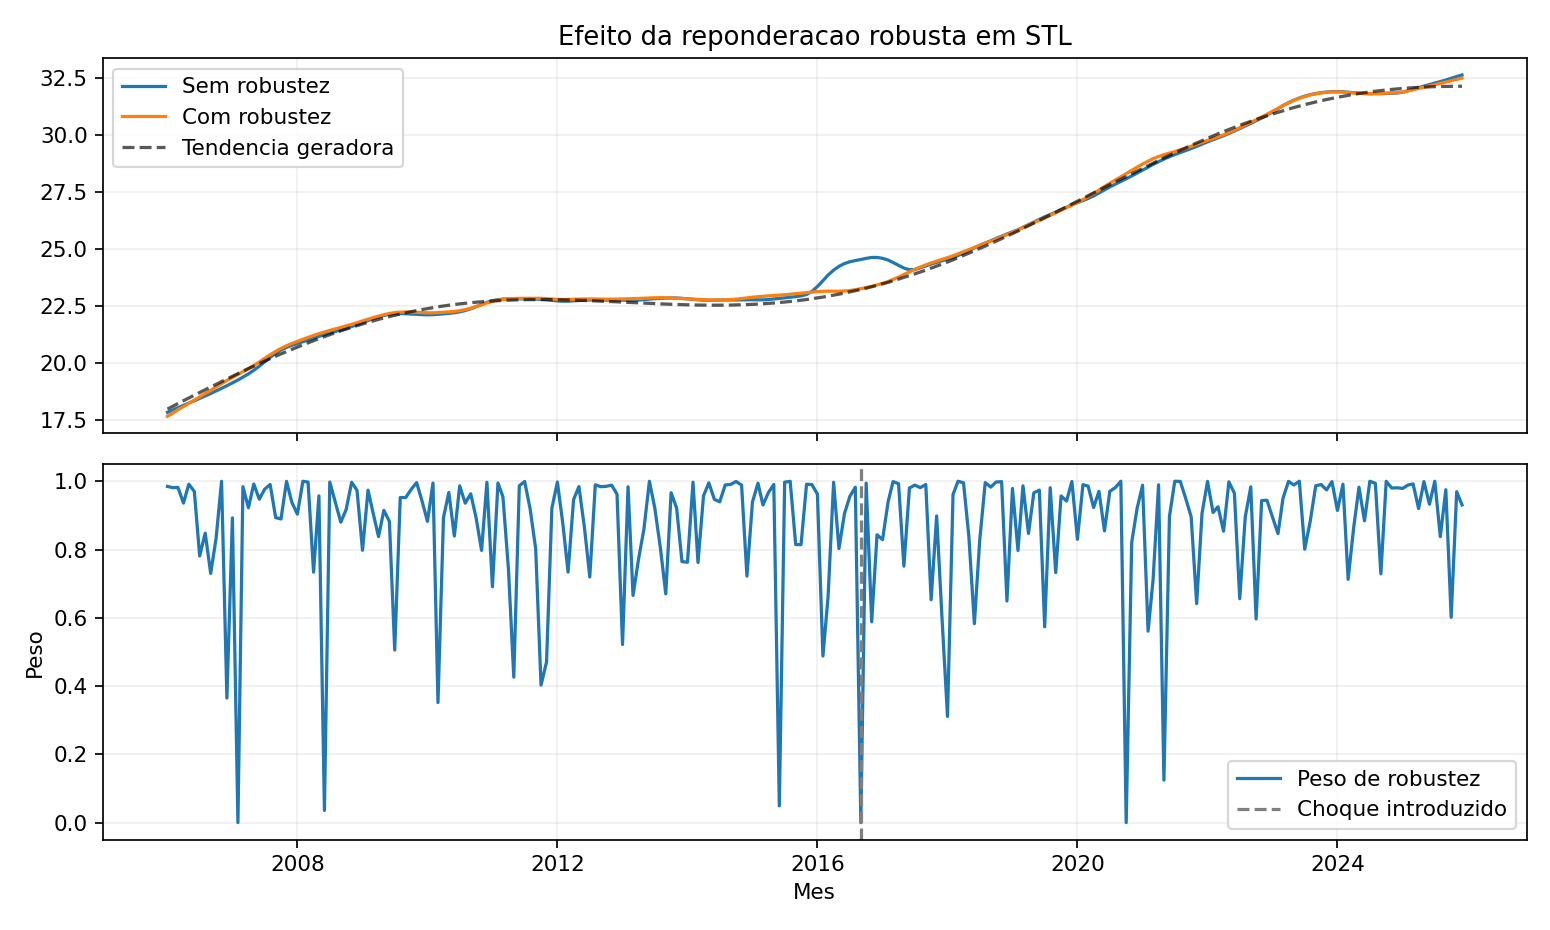

*Figura 3.3 — Tendências estimadas com e sem reponderação e pesos robustos. No choque artificial, o peso robusto chegou a zero; o erro pontual da tendência foi aproximadamente 0,0355 no ajuste robusto, contra 1,3135 no não robusto, **nesta simulação específica**.*

### 8. Limitações, interpretação e uso em previsão

1. **Uma decomposição não é uma previsão.** STL costuma usar informações dos dois lados de um instante (suavização retrospectiva). Se você calcular STL em toda a amostra antes de separar treino e teste, poderá introduzir **vazamento temporal**. Uma avaliação de previsão deve estimar componentes e hiperparâmetros usando somente o passado disponível em cada origem.
2. **A identidade de reconstrução é algébrica.** Como $R_t=y_t-\widehat T_t-\widehat S_t$, a soma dos componentes reconstrói os dados por definição. Isso não implica que o resíduo seja ruído branco.
3. **Componente irregular não é sinônimo de inovação independente.** Examine ACF, mudanças de variância, valores ausentes e rupturas quando necessários.
4. **Dados com irregularidade de calendário:** preencher datas ausentes arbitrariamente ou supor que o índice inteiro representa intervalos físicos regulares distorce o significado do período sazonal.
5. **Robustez não equivale a correção de dados ruins.** Uma anomalia pode ser evento real, e perdas de observação exigem tratamento separado.
6. **Uma sazonalidade por vez.** Se os ciclos diário e semanal forem relevantes simultaneamente, aplicar STL com `period=24` não explicita um componente sazonal independente para `period=168`. Essa limitação motiva MSTL.

### 9. Exercícios com progressão

1. **Conceitual:** por que calcular apenas uma média de cada mês, repetida ao longo de todos os anos, pode ser inadequado quando o padrão sazonal muda?
2. **Algebra:** demonstre a identidade $R_t=y_t-\widehat T_t-\widehat S_t$ e explique por que ela não demonstra ausência de autocorrelação.
3. **Manual:** calcule pesos robustos para $m=1$ e resíduos $0,2,6,9$. Discuta a interpretação de valores de peso iguais a zero.
4. **Pseudocódigo:** descreva sem Python o fluxo “retirar tendência → suavizar sub-séries → passa-baixas → estimar sazonalidade → dessazonalizar → atualizar tendência”.
5. **Implementação:** altere `robust=True` para `False` e compare o erro de tendência apenas na vizinhança do choque simulado. A diferença que observaria em um conjunto de dados real seria suficiente para identificar um valor como erro de medição?
6. **Pesquisa:** esboce como ajustar STL dentro de validação em janela expansiva sem consultar observações posteriores à origem da previsão.

**Pista para o exercício 3:** com $m=1$, o denominador da padronização é $6$; o resíduo de módulo 6 já recebe peso zero.

### 10. Síntese e referências

STL alterna suavizações locais para separar uma tendência flexível e uma sazonalidade que pode evoluir com o tempo. O **passa-baixas** ajuda a evitar que a sazonalidade absorva movimentos lentos, e o **laço robusto** reduz a influência de observações com grandes resíduos. O resultado é uma decomposição aditiva dependente de parâmetros e hipóteses práticas, não um teste de estacionariedade nem um modelo preditivo completo.

- MORETTIN, P. A.; TOLOI, C. M. C. *Análise de séries temporais: modelos lineares univariados*. 3. ed., v. 1. Blucher, 2018. Cap. 3, §3.2, pp. 52–56. **Referência diretamente conferida para tendência, filtros e LOWESS; não para o algoritmo STL completo.**
- CLEVELAND, R. B.; CLEVELAND, W. S.; MCRAE, J. E.; TERPENNING, I. *STL: A Seasonal-Trend Decomposition Procedure Based on Loess*. Journal of Official Statistics, v. 6, n. 1, pp. 3–73, 1990. **Referência clássica para consulta futura; não consultada diretamente nesta redação.**
- `mapeamento-conteudos-series-temporais.md`, *Aula 2 — Parte II — Decomposição STL e MSTL*. **Base de alinhamento curricular, não fonte de equações reproduzidas.**
- Documentação instalada de `statsmodels.tsa.seasonal.STL` e execução de exemplos em Statsmodels 0.14.6: **conferência operacional**.